# GLM analysis

### Loading libraries and data

In [18]:
import os
import os.path as op

import numpy as np
import pandas as pd
import nibabel as nib
import matplotlib.pyplot as plt

from nilearn.glm.first_level import FirstLevelModel
from nilearn.glm import threshold_stats_img
from nilearn.plotting import plot_design_matrix, plot_stat_map, plot_glass_brain, show

In [2]:
# Project directories
notebook_dir = os.path.abspath("")
dataset_path = op.join(notebook_dir, 'dataset')

derivatives_func = op.join(dataset_path, 'derivatives', 'func')
derivatives_anat = op.join(dataset_path, 'derivatives', 'anat')

# Load preprocessed fMRI data
fmri_path = op.join(
    derivatives_func,
    'tfMRI_LANGUAGE_LR_moco_smoothed-4mm.nii.gz'
)

fmri_img = nib.load(fmri_path)

# Anatomical image in MNI space, used as background for all the brain plots
bg_img = op.join(derivatives_anat, 'T1w_mni.nii.gz')

# Acquisition parameters
tr = float(fmri_img.header.get_zooms()[3])
n_scans = fmri_img.shape[-1]

print("fMRI shape:", fmri_img.shape)
print("TR:", tr, "s")

fMRI shape: (91, 109, 91, 311)
TR: 0.7200000286102295 s


### Experimental design

The GLM includes two task regressors, `story` and `math`, representing
the main experimental conditions.

The event timings are adjusted to account for the first five fMRI
volumes removed during preprocessing.

In [3]:
# Load experimental events
events_path = op.join(
    dataset_path,
    'fMRI',
    'tfMRI_LANGUAGE_LR',
    'tfMRI_LANGUAGE_LR_task_onsets.csv'
)

events = pd.read_csv(events_path)

# Select the main experimental conditions
events_glm = events[
    events['trial_type'].isin(['math', 'story'])
].copy()

# Account for the first 5 volumes removed during preprocessing
start_vol = 5
time_shift = start_vol * tr

events_glm['onset'] = events_glm['onset'] - time_shift

# Remove events ending before the retained acquisition
events_glm = events_glm[
    events_glm['onset'] + events_glm['duration'] > 0
].copy()

# Adjust events overlapping the beginning
events_glm['duration'] = (
    events_glm['onset'] + events_glm['duration']
).clip(lower=0) - events_glm['onset'].clip(lower=0)

events_glm['onset'] = events_glm['onset'].clip(lower=0)

# Sort events
events_glm = events_glm.sort_values('onset').reset_index(drop=True)

events_glm

,onset,duration,trial_type
0,0.000,24.911,story
1,26.495,12.241,math
2,38.970,12.312,math
3,52.924,27.147,story
4,81.606,12.667,math
5,94.520,12.542,math
6,108.674,26.070,story
7,136.330,11.844,math
8,148.445,12.528,math
9,161.253,9.838,math


### GLM specification and estimation

A first-level GLM is fitted to the preprocessed fMRI data using Nilearn. A first-level (single-subject, single-run) analysis is the only reasonable level here, since we have one subject and one run.

The experimental regressors are convolved with the canonical SPM
hemodynamic response function (HRF) to model the expected BOLD response.

Temporal autocorrelation in the residuals is modeled using an AR(1)
noise model. To account for low-frequency fluctuations in the BOLD signal, cosine drift regressors are included in the design matrix, with a high-pass
cutoff frequency of 0.01 Hz. These regressors model slow temporal variations that are not directly attributed to the experimental conditions.

The six rigid-body motion parameters estimated by MCFLIRT during motion correction (3 rotations and 3 translations per volume) are added to the design matrix as nuisance regressors. Realignment does not remove all motion-related effects from the BOLD signal, and including these regressors prevents that residual signal related to motion is attributed to the task conditions.

In [4]:
# Motion parameters estimated by MCFLIRT (one row per volume, 311 volumes)
motion_names = ['rot_x', 'rot_y', 'rot_z', 'trans_x', 'trans_y', 'trans_z']
motion = pd.DataFrame(
    np.loadtxt(op.join(derivatives_func, 'tfMRI_LANGUAGE_LR_moco.par')),
    columns=motion_names
)

# Specify the GLM
fmri_glm = FirstLevelModel(
    t_r=tr,
    noise_model='ar1',
    standardize=False,
    hrf_model='spm',
    drift_model='cosine',
    high_pass=0.01
)

# Fit the GLM (motion parameters added as confound regressors)
fmri_glm = fmri_glm.fit(fmri_img, events_glm, confounds=motion)

### Design matrix

The design matrix contains the two task-related regressors (`math` and `story`), the six motion regressors, four cosine drift regressors, and a constant term. Each row corresponds to one fMRI volume (311 in total) and each column to one regressor.

The second plot shows the expected BOLD time courses of the two task regressors, i.e. the task blocks convolved with the canonical HRF. The story and math blocks alternate throughout the run, and the math blocks come in pairs of about 12 s each, so that their total duration matches that of the story blocks. The two regressors are never both close to zero: the design contains no rest periods, and the only time outside the two conditions is made of the short cues and gaps between blocks. 

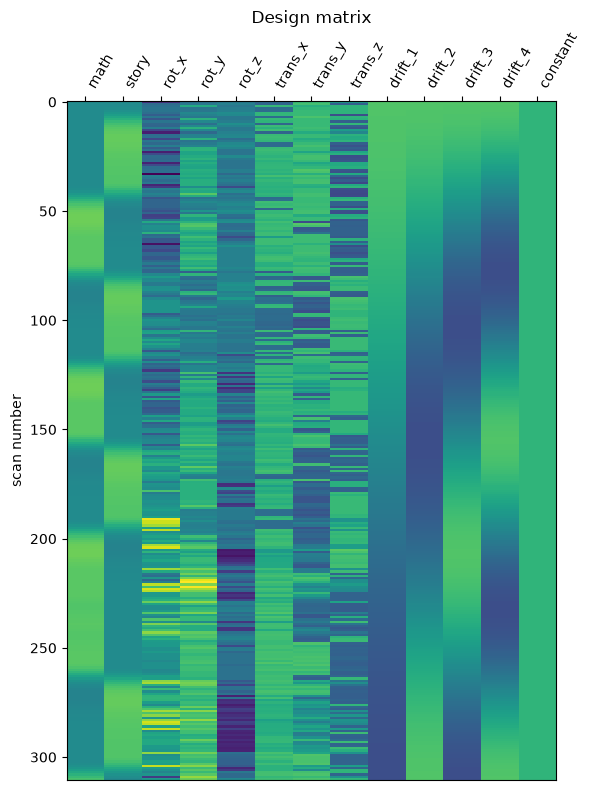

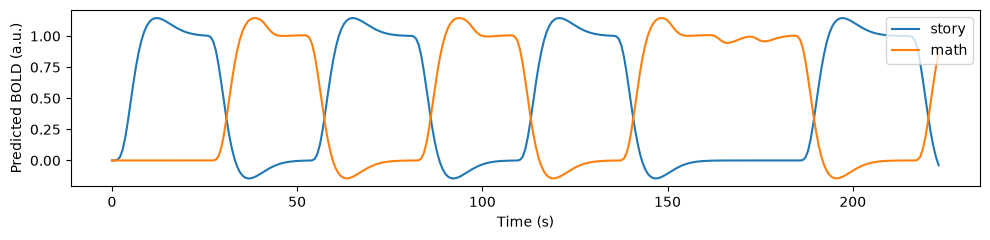

In [6]:
# Extract and visualize the design matrix
design_matrix = fmri_glm.design_matrices_[0]

fig, ax = plt.subplots(figsize=(6, 8))
plot_design_matrix(design_matrix, ax=ax)
ax.set_title('Design matrix', fontsize=12)
plt.tight_layout()
plt.show()

# Expected BOLD time courses of the two task regressors
fig, ax = plt.subplots(figsize=(10, 2.5))
frame_times = np.arange(n_scans) * tr
ax.plot(frame_times, design_matrix['story'], label='story')
ax.plot(frame_times, design_matrix['math'], label='math')
ax.set(xlabel='Time (s)', ylabel='Predicted BOLD (a.u.)')
ax.legend(loc='upper right')
plt.tight_layout()
plt.show()

### Correlation matrix

The correlation matrix is computed to assess the linear dependence
between the regressors of the design matrix.

High correlations between regressors may indicate multicollinearity,
making it more difficult to estimate their individual contributions
to the BOLD signal.

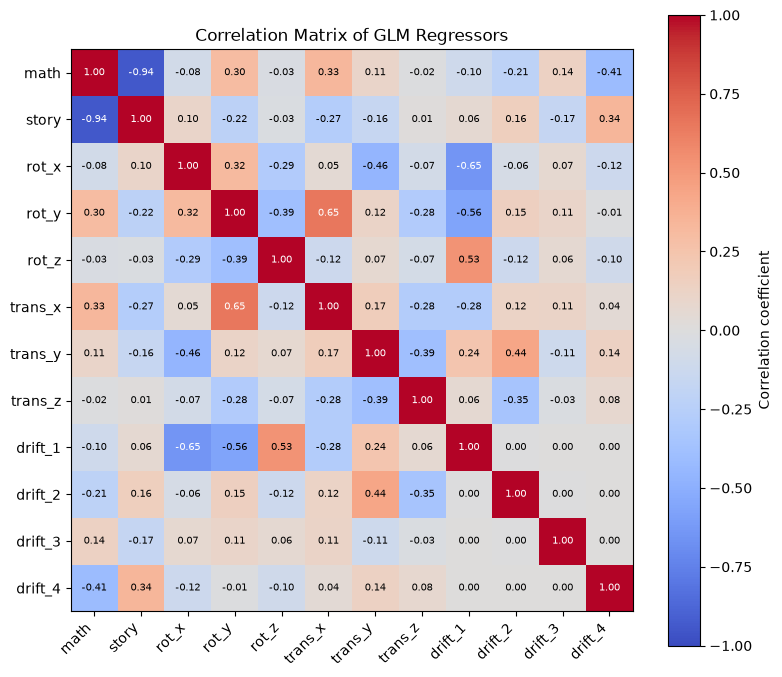

Correlation between math and story: -0.943


In [9]:
# Compute correlation matrix (the constant has zero variance so excluded)
correlation_matrix = design_matrix.drop(columns='constant').corr()

# Plot correlation matrix
fig, ax = plt.subplots(figsize=(8, 7))
im = ax.imshow(correlation_matrix, cmap='coolwarm', vmin=-1, vmax=1)
fig.colorbar(im, ax=ax, label='Correlation coefficient')

labels = correlation_matrix.columns
ax.set_xticks(range(len(labels)))
ax.set_xticklabels(labels, rotation=45, ha='right')
ax.set_yticks(range(len(labels)))
ax.set_yticklabels(labels)

# Write the coefficient in each cell
for i in range(len(labels)):
    for j in range(len(labels)):
        val = correlation_matrix.iloc[i, j]
        txt = round(val, 2) + 0.0   
        ax.text(j, i, f'{txt:.2f}', ha='center', va='center', fontsize=7,
                color='white' if abs(val) > 0.6 else 'black')

ax.set_title('Correlation Matrix of GLM Regressors')
plt.tight_layout()
plt.show()

# Correlation between the main task regressors
print(
    "Correlation between math and story:",
    round(correlation_matrix.loc['math', 'story'], 3)
)

### Interpretation

The correlation matrix shows a strong negative correlation between
the math and story regressors (r = −0.943). This is consistent with
the experimental design, in which the two conditions alternate over
time and there is no rest baseline. Story + math is nearly constant so the two tasl regressors are nearly collinear with the intercept. 

Such a strong anticorrelation indicates that the two regressors contain
limited independent information, which can make it more difficult to
estimate their individual effects. Since the two conditions are almost
complementary, it becomes difficult for the GLM to distinguish how
much of the BOLD signal should be attributed to each condition and
how much to the baseline (represented by the constant regressor).
This can increase the uncertainty of the estimated coefficients.

However, this does not necessarily prevent a direct comparison between
the two conditions. Even if the individual coefficients $\beta_{story}$ and $\beta_{math}$ are estimated with a large variance, their difference can still be estimated through the story − math contrast, in which the baseline contribution cancels out.

The additional cosine drift regressors account for low-frequency
temporal fluctuations. Their correlations with the task regressors
are generally low to moderate, suggesting that they do not closely
reproduce the task-related temporal patterns. The motion regressors show weak to moderate correlations with the task: the subjects moved slightly differently in the two tasks. Including them reduces motion-related false positives at the cost of possibly removing a small part of the task signal.

The diagonal elements of the correlation matrix are equal to 1,
since each nonconstant regressor is perfectly correlated with itself.
The constant regressor is excluded from the correlation matrix because it has zero variance.

Overall, the correlation structure reflects the alternating block
design. Although the strong anticorrelation may reduce the precision
of individual coefficient estimates, it does not invalidate the GLM
and still allows a meaningful comparison between mathematical and
language processing through the story − math contrast.

### Statistical maps of task-related regressors

The fitted GLM is used to compute Z-statistic maps for the two experimental conditions, `math` and `story`.

For each regressor, the null hypothesis is that its corresponding coefficient is equal to zero:

- Math: $H_0: \beta_{\mathrm{math}} = 0$
- Story: $H_0: \beta_{\mathrm{story}} = 0$

Positive Z-values indicate positive associations between the task regressor and the BOLD signal, while negative Z-values indicate negative associations.

False Discovery Rate (FDR) correction is applied at q = 0.05 to account for multiple voxelwise comparisons.

In [10]:
# Compute Z-statistic maps for each task-related regressor
z_map_math = fmri_glm.compute_contrast(
    'math',
    output_type='z_score'
)

z_map_story = fmri_glm.compute_contrast(
    'story',
    output_type='z_score'
)

# Apply FDR correction
math_fdr, math_threshold = threshold_stats_img(
    z_map_math,
    alpha=0.05,
    height_control='fdr',
    two_sided=True
)

story_fdr, story_threshold = threshold_stats_img(
    z_map_story,
    alpha=0.05,
    height_control='fdr',
    two_sided=True
)

print("Math FDR threshold:", math_threshold)
print("Story FDR threshold:", story_threshold)

Math FDR threshold: 3.9840983616481846
Story FDR threshold: inf


/opt/conda/lib/python3.13/site-packages/nilearn/glm/thresholding.py:297: UserWarning: The given float value must not exceed 4.710677728108166. But, you have given threshold=inf.
  stat_img = threshold_img(


### Visualization of statistical maps

Story: no voxels survive FDR correction at q = 0.05.


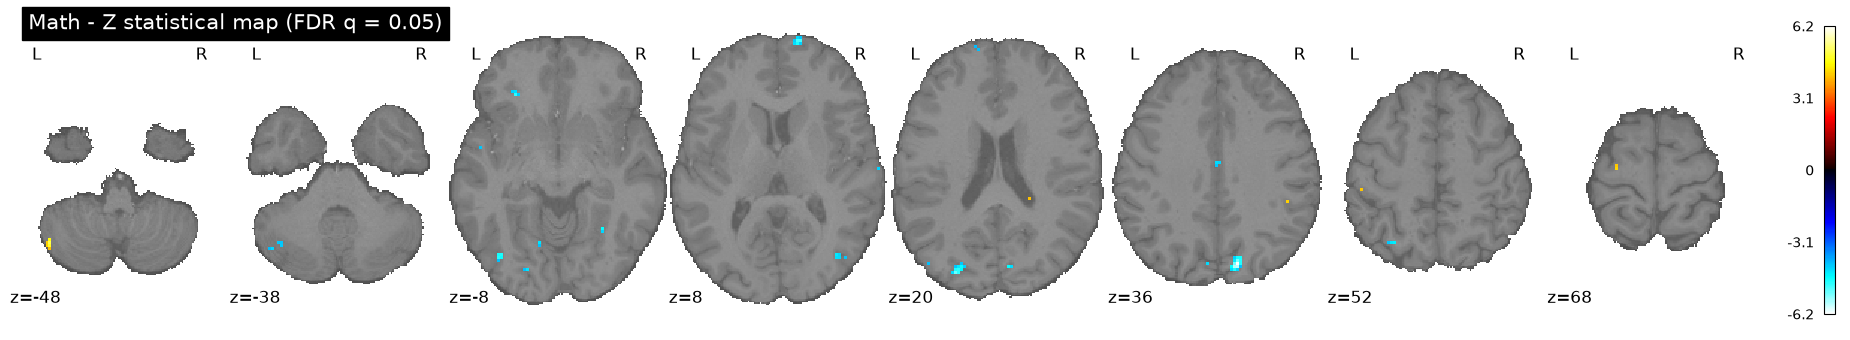

In [14]:
# Math statistical map
plot_stat_map(
    math_fdr,
    bg_img=bg_img,
    black_bg=False,
    title='Math - Z statistical map (FDR q = 0.05)',
    display_mode='z',
    cut_coords=8,
    threshold=0,
    cmap='cold_hot',
    colorbar=True
)

# Story statistical map
if np.isfinite(story_threshold):
    plot_stat_map(
        story_fdr,
        bg_img=bg_img,
        black_bg=False,
        title='Story - Z statistical map (FDR q = 0.05)',
        display_mode='z',
        cut_coords=8,
        threshold=0,
        cmap='cold_hot',
        colorbar=True
    )
else:
    print("Story: no voxels survive FDR correction at q = 0.05.")

show()

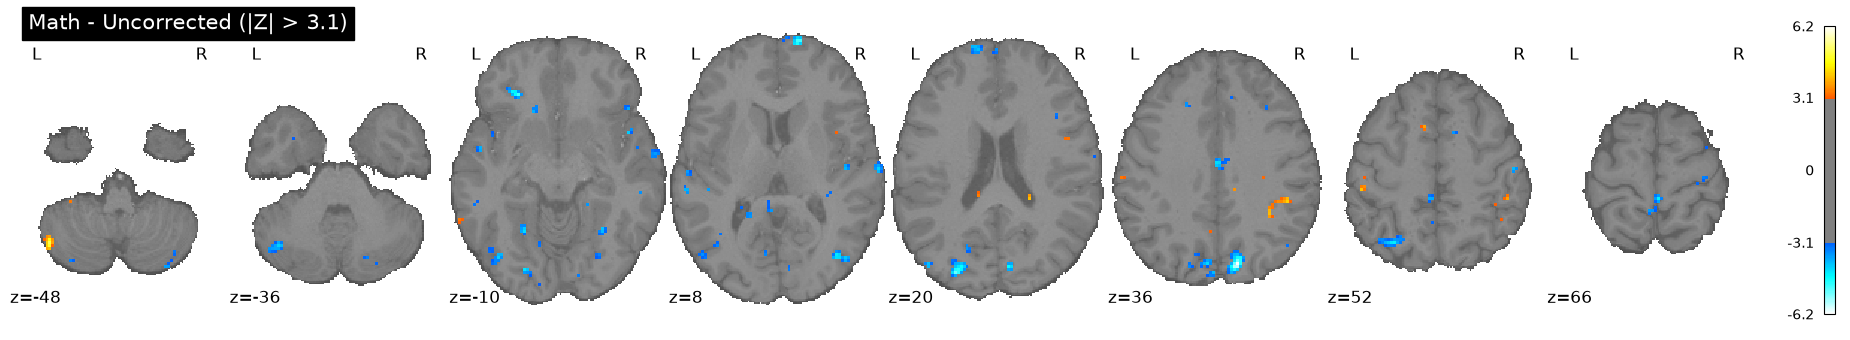

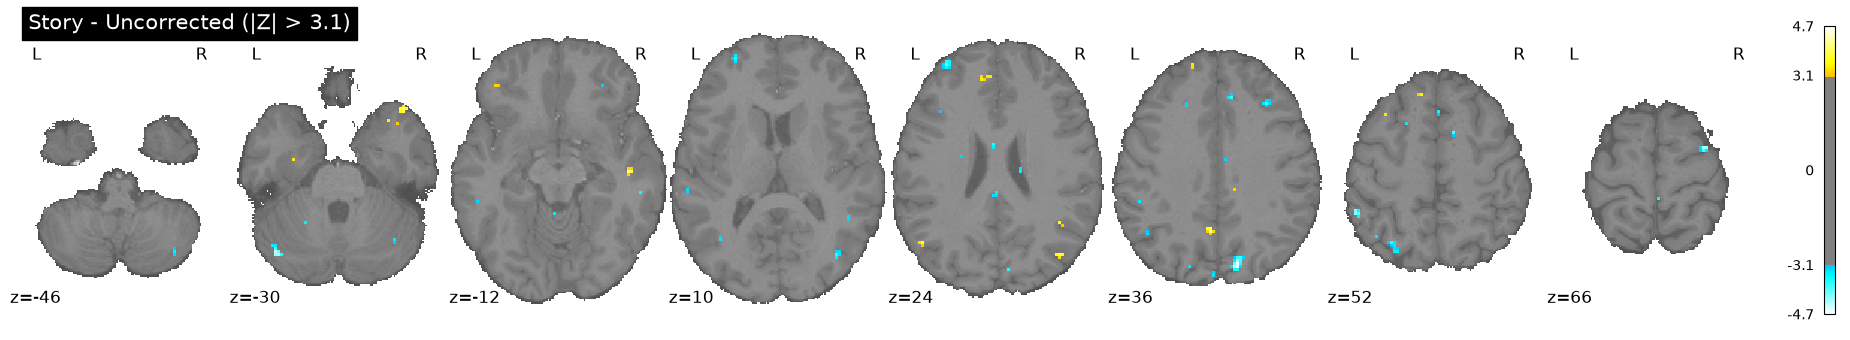

In [15]:
plot_stat_map(
    z_map_math,
    bg_img=bg_img,
    black_bg=False,
    title='Math - Uncorrected (|Z| > 3.1)',
    display_mode='z',
    cut_coords=8,
    threshold=3.1,
    cmap='cold_hot',
    colorbar=True
)

plot_stat_map(
    z_map_story,
    bg_img=bg_img,
    black_bg=False,
    title='Story - Uncorrected (|Z| > 3.1)',
    display_mode='z',
    cut_coords=8,
    threshold=3.1,
    cmap='cold_hot',
    colorbar=True
)

show()

### Interpretation

The statistical maps show the spatial distribution of BOLD signal changes associated with mathematical and story processing. After FDR correction at q = 0.05, the math regressor shows statistically significant effects, with a Z-threshold of approximately 3.22. Most visible significant effects are negative.
In contrast, no voxels survive FDR correction for the story regressor. However, the uncorrected maps (|Z| > 3.1) reveal some spatially limited effects associated with story processing.

These results should be interpreted cautiously because the math and story regressors are strongly anticorrelated, making their individual coefficients difficult to estimate independently of the baseline.
Importantly, negative Z-values do not necessarily indicate reduced activity relative to the other experimental condition. The individual statistical maps test each coefficient against zero, whereas the direct comparison between the two tasks requires a contrast.


## Story vs Math contrast

To directly compare brain responses during story comprehension and mathematical processing, the following contrast is defined:

$\beta_{\mathrm{story}}-\beta_{\mathrm{math}}$

The contrast vector assigns +1 to the story regressor, −1 to the math regressor, and zero to the remaining regressors.
Positive Z-values indicate stronger responses during story processing, whereas negative Z-values indicate stronger responses during mathematical processing.

False Discovery Rate (FDR) correction is applied at q = 0.05 to identify statistically significant differences between the two conditions.

In [16]:
# Define the story - math contrast
contrast_vector = np.zeros(len(design_matrix.columns))

contrast_vector[design_matrix.columns.get_loc('story')] = 1
contrast_vector[design_matrix.columns.get_loc('math')] = -1

print("Regressors:", list(design_matrix.columns))
print("Contrast vector:", contrast_vector)

# Compute contrast Z-map
z_map_contrast = fmri_glm.compute_contrast(
    contrast_vector,
    output_type='z_score'
)

# Apply FDR correction
contrast_fdr, contrast_threshold = threshold_stats_img(
    z_map_contrast,
    alpha=0.05,
    height_control='fdr',
    two_sided=True
)

print("Contrast FDR threshold:", contrast_threshold)

Regressors: ['math', 'story', 'rot_x', 'rot_y', 'rot_z', 'trans_x', 'trans_y', 'trans_z', 'drift_1', 'drift_2', 'drift_3', 'drift_4', 'constant']
Contrast vector: [-1.  1.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.]
Contrast FDR threshold: 2.589344866323985


### Visualization of the contrast map

Positive Z-values represent regions responding more strongly during story comprehension, while negative Z-values represent regions responding more strongly during mathematical processing.

The FDR-corrected map is used to identify statistically significant differences, while the uncorrected map is also displayed for exploratory visualization.

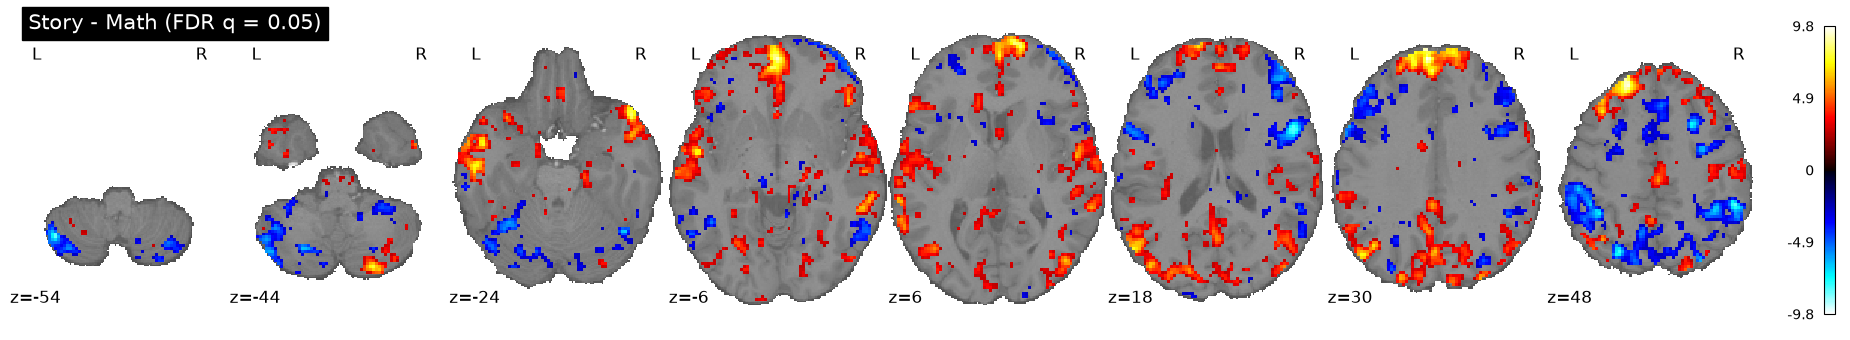

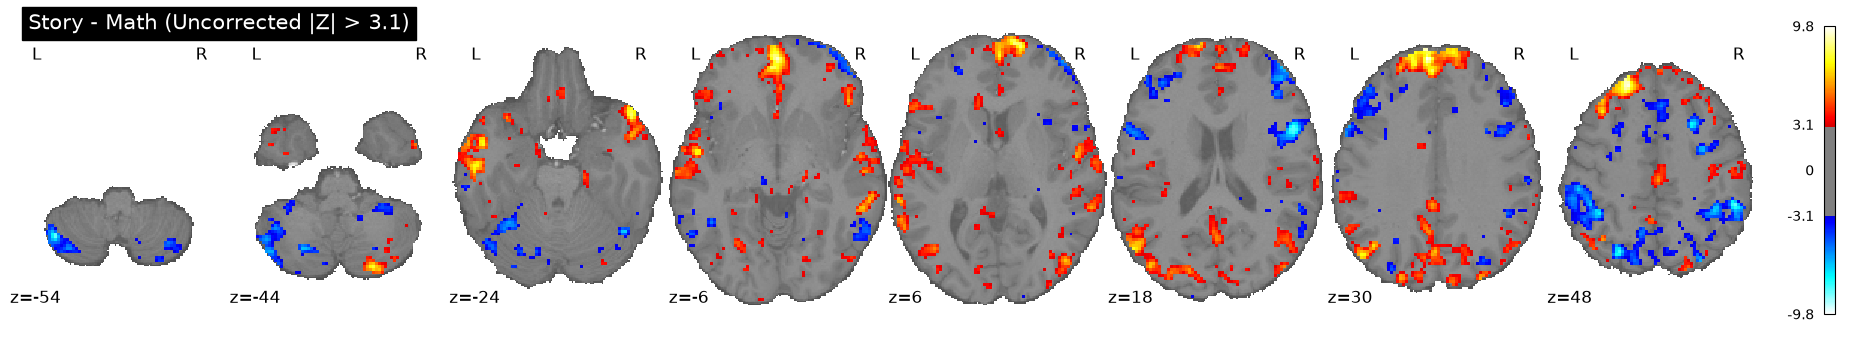

In [17]:
# FDR-corrected contrast map
if np.isfinite(contrast_threshold):
    plot_stat_map(
        contrast_fdr,
        bg_img=bg_img,
        black_bg=False,
        title='Story - Math (FDR q = 0.05)',
        display_mode='z',
        cut_coords=8,
        threshold=0,
        cmap='cold_hot',
        colorbar=True
    )
else:
    print("No voxels survive FDR correction for the story - math contrast.")

# Uncorrected contrast map
plot_stat_map(
    z_map_contrast,
    bg_img=bg_img,
    black_bg=False,
    title='Story - Math (Uncorrected |Z| > 3.1)',
    display_mode='z',
    cut_coords=8,
    threshold=3.1,
    cmap='cold_hot',
    colorbar=True
)

show()

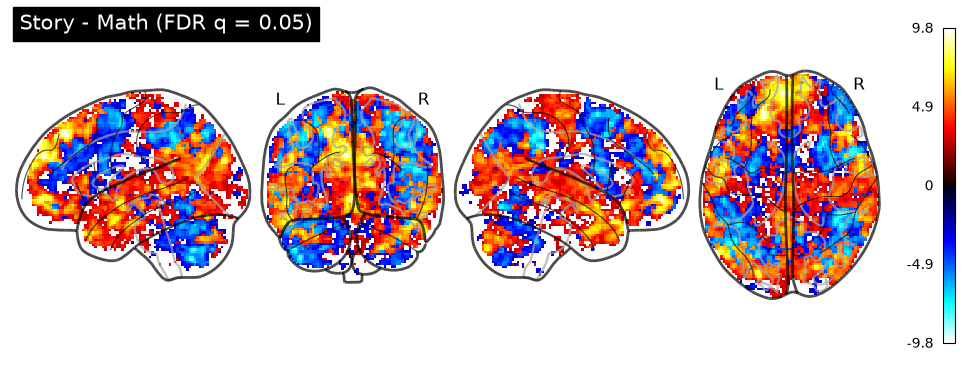

In [21]:
plot_glass_brain(
    contrast_fdr,
    threshold=0,
    plot_abs=False,      # keep positive (story) and negative (math) values
    colorbar=True,
    cmap='cold_hot',
    display_mode='lyrz',
    title='Story - Math (FDR q = 0.05)'
)
show()

### Interpretation

The contrast vector used is c = [−1, 1, 0, …, 0], i.e. +1 for story, −1 for math and 0 for all the nuisance regressors. The story − math contrast reveals widespread differences in BOLD responses between the two experimental conditions: the contrast effects are strong (|Z| up to ≈ 10).

Since FDR adapts to the number of truly active voxels, the resulting threshold is low and a large part of the brain survives correction. This indicates statistically significant differences between story comprehension and mathematical processing. Positive Z-values correspond to regions showing stronger responses during story processing, whereas negative Z-values correspond to regions showing stronger responses during mathematical processing.
Unlike the individual regressor maps, the contrast directly compares the two experimental conditions. This is particularly informative given the strong anticorrelation between the task regressors.

The spatial distribution of significant positive and negative clusters suggests the involvement of distinct functional systems.